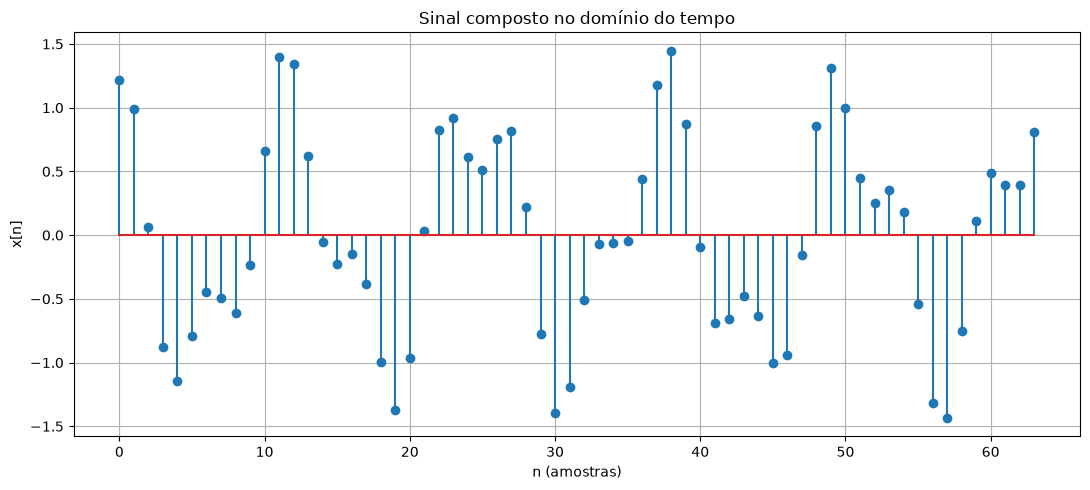

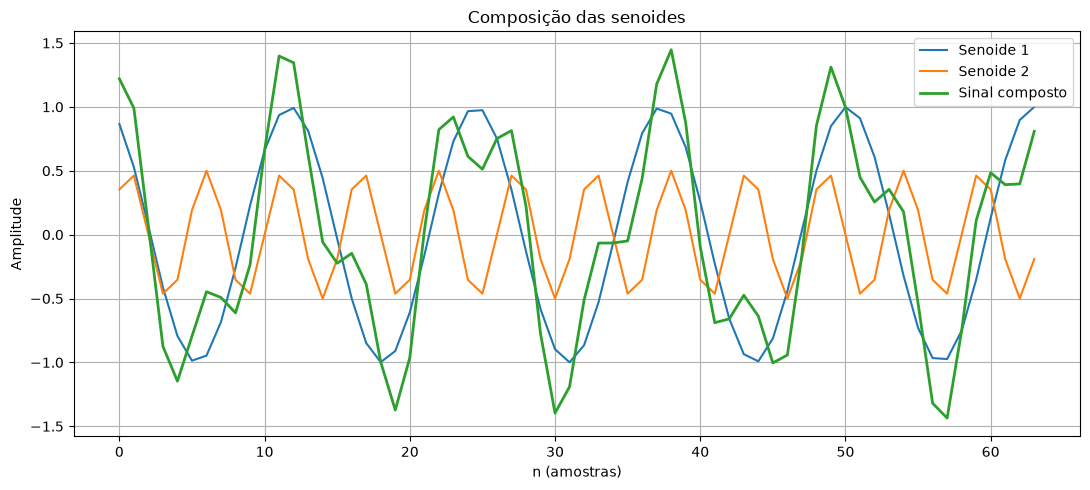

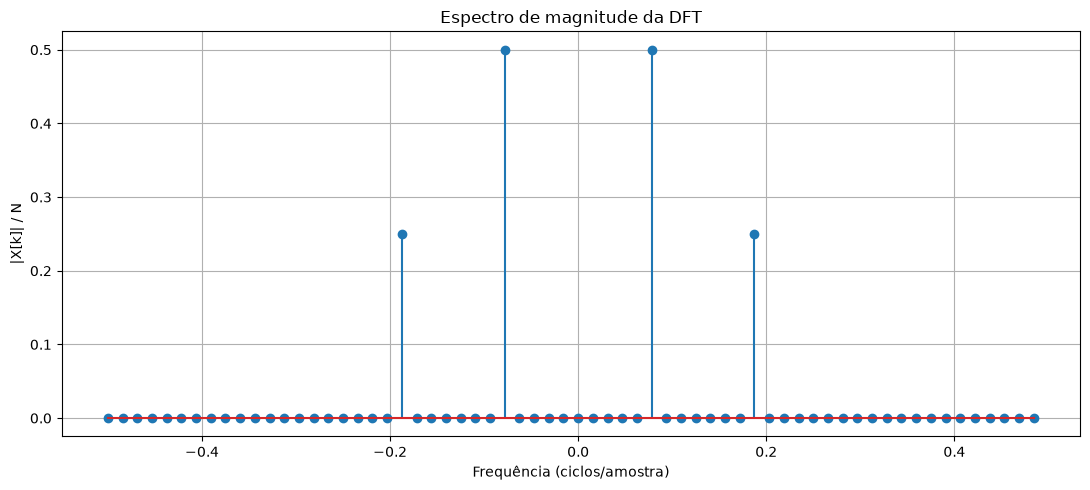

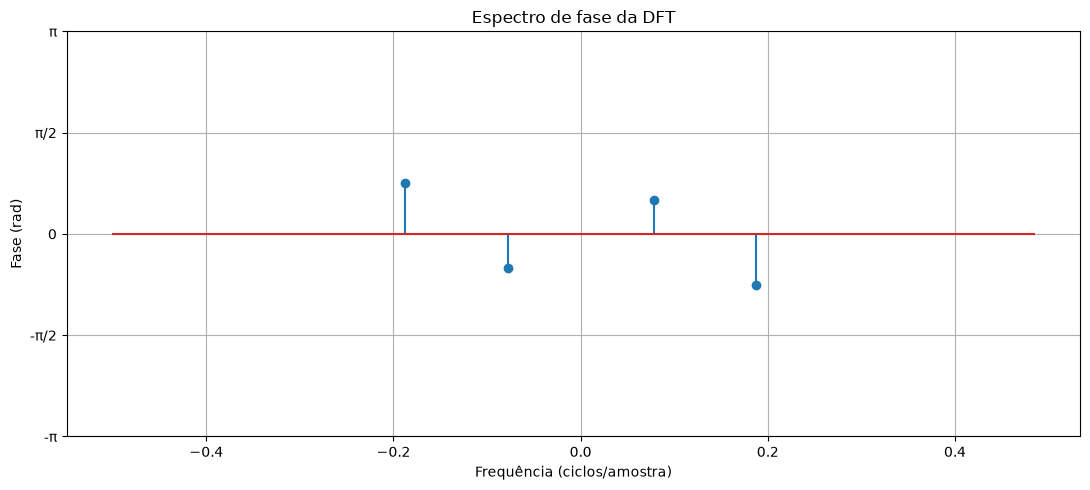

ANÁLISE DA DFT
Número de amostras: 64
Frequência da senoide 1: 0.07812 ciclos/amostra
Frequência da senoide 2: 0.18750 ciclos/amostra

Picos identificados no espectro:

Bin k = 5
Frequência: 0.07812 ciclos/amostra
Frequência angular: 0.49087 rad/amostra
Magnitude normalizada: 0.5000
Fase: 0.5236 rad

Bin k = 12
Frequência: 0.18750 ciclos/amostra
Frequência angular: 1.17810 rad/amostra
Magnitude normalizada: 0.2500
Fase: -0.7854 rad

Verificação da DFT inversa
Erro máximo de reconstrução: 1.8711725503e-14

Simulação concluída!


In [1]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. CONFIGURAÇÕES DO SINAL
# ============================================================

N = 64                      # Número de amostras
n = np.arange(N)            # Índices das amostras

# Parâmetros da primeira senoide
A1 = 1.0
k1 = 5
phi1 = np.pi / 6

# Parâmetros da segunda senoide
A2 = 0.5
k2 = 12
phi2 = -np.pi / 4

# Frequências angulares (rad/amostra)
w1 = 2 * np.pi * k1 / N
w2 = 2 * np.pi * k2 / N


# ============================================================
# 2. GERAÇÃO DO SINAL
# ============================================================

x1 = A1 * np.cos(w1 * n + phi1)
x2 = A2 * np.cos(w2 * n + phi2)

# Sinal composto
x = x1 + x2


# ============================================================
# 3. CÁLCULO DA DFT
# ============================================================

def calcular_dft(x):
    """
    Calcula a DFT diretamente pela definição matemática:

    X[k] = sum(x[n] * exp(-j*2*pi*k*n/N))
    """

    N = len(x)

    k = np.arange(N)
    n = np.arange(N)

    # Matriz de coeficientes exponenciais
    matriz = np.exp(
        -1j * 2 * np.pi * np.outer(k, n) / N
    )

    # Multiplicação matricial
    X = matriz @ x

    return X


X = calcular_dft(x)


# ============================================================
# 4. ESPECTRO DE MAGNITUDE E FASE
# ============================================================

# Normalização da magnitude
magnitude = np.abs(X) / N

# Espectro de fase
fase = np.angle(X)

# Frequências normalizadas (ciclos/amostra)
frequencias = np.fft.fftfreq(N)

# Frequências angulares (rad/amostra)
omega = 2 * np.pi * frequencias

# Reorganização dos espectros para exibição
frequencias_shift = np.fft.fftshift(frequencias)
omega_shift = np.fft.fftshift(omega)

magnitude_shift = np.fft.fftshift(magnitude)
fase_shift = np.fft.fftshift(fase)


# ============================================================
# 5. GRÁFICO DO SINAL NO DOMÍNIO DO TEMPO
# ============================================================

plt.figure(figsize=(11, 5))

plt.stem(n, x)

plt.title("Sinal composto no domínio do tempo")
plt.xlabel("n (amostras)")
plt.ylabel("x[n]")

plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 6. GRÁFICO DAS SENOIDES INDIVIDUAIS E COMPOSTA
# ============================================================

plt.figure(figsize=(11, 5))

plt.plot(n, x1, label="Senoide 1")
plt.plot(n, x2, label="Senoide 2")
plt.plot(n, x, label="Sinal composto", linewidth=2)

plt.title("Composição das senoides")
plt.xlabel("n (amostras)")
plt.ylabel("Amplitude")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 7. ESPECTRO DE MAGNITUDE
# ============================================================

plt.figure(figsize=(11, 5))

plt.stem(frequencias_shift, magnitude_shift)

plt.title("Espectro de magnitude da DFT")
plt.xlabel("Frequência (ciclos/amostra)")
plt.ylabel("|X[k]| / N")

plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 8. ESPECTRO DE FASE
# ============================================================

# Desconsidera fases de componentes com magnitude muito pequena
fase_plot = fase_shift.copy()
fase_plot[magnitude_shift < 1e-6] = np.nan

plt.figure(figsize=(11, 5))

plt.stem(frequencias_shift, fase_plot)

plt.title("Espectro de fase da DFT")
plt.xlabel("Frequência (ciclos/amostra)")
plt.ylabel("Fase (rad)")

plt.yticks(
    [-np.pi, -np.pi/2, 0, np.pi/2, np.pi],
    ["-π", "-π/2", "0", "π/2", "π"]
)

plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 9. IDENTIFICAÇÃO DAS FREQUÊNCIAS
# ============================================================

print("ANÁLISE DA DFT")
print("=" * 45)

print(f"Número de amostras: {N}")
print(f"Frequência da senoide 1: {k1/N:.5f} ciclos/amostra")
print(f"Frequência da senoide 2: {k2/N:.5f} ciclos/amostra")

print("\nPicos identificados no espectro:")

# Identificação dos picos positivos
for k in [k1, k2]:
    print(f"\nBin k = {k}")
    print(f"Frequência: {k/N:.5f} ciclos/amostra")
    print(f"Frequência angular: {2*np.pi*k/N:.5f} rad/amostra")
    print(f"Magnitude normalizada: {magnitude[k]:.4f}")
    print(f"Fase: {fase[k]:.4f} rad")


# ============================================================
# 10. VERIFICAÇÃO PELA DFT INVERSA
# ============================================================

def calcular_idft(X):
    """
    Calcula a transformada discreta inversa de Fourier:

    x[n] = (1/N) * sum(X[k] * exp(j*2*pi*k*n/N))
    """

    N = len(X)

    k = np.arange(N)
    n = np.arange(N)

    matriz = np.exp(
        1j * 2 * np.pi * np.outer(n, k) / N
    )

    x_reconstruido = (matriz @ X) / N

    return x_reconstruido


x_reconstruido = calcular_idft(X)

erro = np.max(np.abs(x - x_reconstruido))

print("\nVerificação da DFT inversa")
print(f"Erro máximo de reconstrução: {erro:.10e}")

print("\nSimulação concluída!")
